X shape: (2000, 2)
y shape: (2000,)


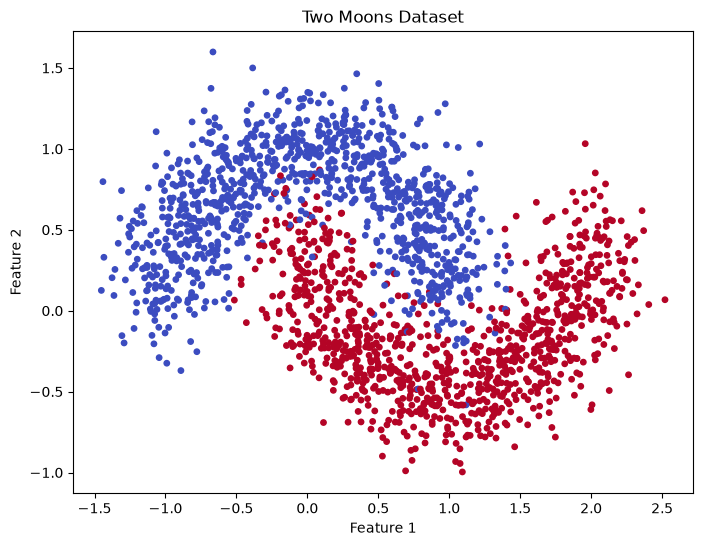

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

X, y = make_moons(
    n_samples=2000,
    noise=0.2,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=15)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two Moons Dataset")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# First: separate training data from temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second: split temporary data into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (1400, 2) (1400,)
Validation: (300, 2) (300,)
Test: (300, 2) (300,)


In [8]:
# Calculate the mean and standard deviation of the training data
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

# Avoid division by zero if a feature has zero variance
std[std == 0] = 1.0

# Normalize the training, validation, and test data
X_train_normalized = (X_train - mean) / std
X_val_normalized = (X_val - mean) / std
X_test_normalized = (X_test - mean) / std

print("Training mean:", np.mean(X_train_normalized, axis=0))
print("Validation mean:", np.mean(X_val_normalized, axis=0))
print("Test mean:", np.mean(X_test_normalized, axis=0))

Training mean: [-2.05787768e-16  6.89012339e-16]
Validation mean: [ 0.00780497 -0.01380786]
Test mean: [ 0.00199409 -0.00768385]


In [9]:
print("Mean:", np.mean(X_train_normalized, axis=0))
print("Std:", np.std(X_train_normalized, axis=0))

print("Shapes:")
print(X_train_normalized.shape)
print(X_val_normalized.shape)
print(X_test_normalized.shape)

Mean: [-2.05787768e-16  6.89012339e-16]
Std: [1. 1.]
Shapes:
(1400, 2)
(300, 2)
(300, 2)
